<a href="https://colab.research.google.com/github/Pulakspbl/Machine-learning-in-Python-with-scikit-learn/blob/main/Module_7_Evaluating_Model_Performance/Module_7_2_Comparing_model_performance_with_a_simple_baseline_Exercise_M7_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Exercise M7.01

In this exercise we will define dummy classification baselines and use them as
reference to assess the relative predictive performance of a given model of
interest.

We illustrate those baselines with the help of the Adult Census dataset, using
only the numerical features for the sake of simplicity.

In [3]:
import pandas as pd
url = "https://raw.githubusercontent.com/INRIA/scikit-learn-mooc/main/datasets/adult-census-numeric-all.csv"
adult_census = pd.read_csv(url)
data, target = adult_census.drop(columns="class"), adult_census["class"]

First, define a `ShuffleSplit` cross-validation strategy taking half of the
samples as a testing at each round. Let us use 10 cross-validation rounds.

In [5]:
from sklearn.model_selection import ShuffleSplit
cv = ShuffleSplit(n_splits=10, test_size=0.2, random_state=0)

Next, create a machine learning pipeline composed of a transformer to standardize the data followed by a logistic regression classifier.


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        )

Compute the cross-validation (test) scores for the classifier on this dataset. Store the results pandas Series as we did in the previous notebook.


In [7]:
from sklearn.model_selection import cross_validate
cv_results = cross_validate(
                model,
                data, target,
                cv=cv,
                scoring="accuracy"
            )

import pandas as pd

scores = pd.Series(cv_results["test_score"])
print("Logistic Regression Scores:")
print(scores)
print(f"Mean Accuracy: {scores.mean():.4f}")

Logistic Regression Scores:
0    0.812263
1    0.813901
2    0.818610
3    0.808271
4    0.808169
5    0.816767
6    0.808271
7    0.812570
8    0.814311
9    0.816767
dtype: float64
Mean Accuracy: 0.8130


Now, compute the cross-validation scores of a dummy classifier that constantly
predicts the most frequent class observed the training set. Please refer to
the online documentation for the [sklearn.dummy.DummyClassifier
](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)
class.

Store the results in a second pandas Series.

In [8]:
from sklearn.dummy import DummyClassifier

model_dummy = DummyClassifier(strategy='most_frequent')
cv_results_dummy = cross_validate(
                    model_dummy,
                    data,
                    target,
                    cv=cv,
                    scoring='accuracy'
                    )

scores_dummy = pd.Series(cv_results_dummy['test_score'])
print("Dummy classifier Scores:")
print(scores_dummy)
print(f"Mean Accuracy: {scores_dummy.mean():.4f}")

Dummy classifier Scores:
0    0.759546
1    0.754120
2    0.763947
3    0.758727
4    0.760262
5    0.761081
6    0.754018
7    0.759648
8    0.764971
9    0.765790
dtype: float64
Mean Accuracy: 0.7602


Now that we collected the results from the baseline and the model, concatenate the test scores as columns a single pandas dataframe.


In [9]:
comparison_df = pd.DataFrame({
    "Logistic Regression": scores,
    "Dummy (Most Frequent)": scores_dummy
})

print("\nPerformance Comparison:")
print(comparison_df.mean())


Performance Comparison:
Logistic Regression      0.812990
Dummy (Most Frequent)    0.760211
dtype: float64



Next, plot the histogram of the cross-validation test scores for both models
with the help of [pandas built-in plotting
function](https://pandas.pydata.org/pandas-docs/stable/user_guide/visualization.html#histograms).

What conclusions do you draw from the results?

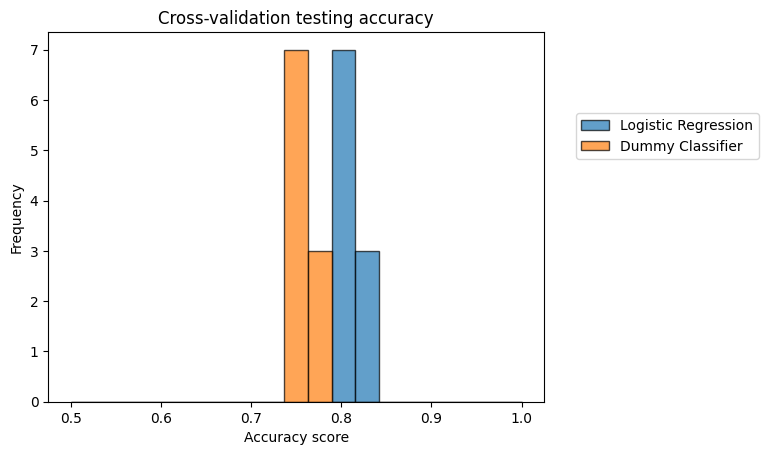

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Combine both score series into a single DataFrame
all_scores = pd.DataFrame({
    "Logistic Regression": scores,
    "Dummy Classifier": scores_dummy
})

# 2. Define bins suitable for accuracy scores (between 0.5 and 1.0)
bins = np.linspace(start=0.5, stop=1.0, num=20)

# 3. Plot the histogram
all_scores.plot.hist(bins=bins, alpha=0.7, edgecolor="black")
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
plt.xlabel("Accuracy score")
plt.ylabel("Frequency")
_ = plt.title("Cross-validation testing accuracy")
plt.show()

Change the `strategy` of the dummy classifier to `"stratified"`, compute the
results. Similarly compute scores for `strategy="uniform"` and then the  plot
the distribution together with the other results.

Are those new baselines better than the previous one? Why is this the case?

Please refer to the scikit-learn documentation on
[sklearn.dummy.DummyClassifier](
https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)
to find out about the meaning of the `"stratified"` and `"uniform"`
strategies.

In [11]:
# Stratified Strategy
model_dummy_stratified = DummyClassifier(strategy="stratified", random_state=42)
cv_results_stratified = cross_validate(
    model_dummy_stratified, data, target, cv=cv, scoring="accuracy"
)
scores_stratified = pd.Series(cv_results_stratified["test_score"])

# Uniform Strategy
model_dummy_uniform = DummyClassifier(strategy="uniform", random_state=42)
cv_results_uniform = cross_validate(
    model_dummy_uniform, data, target, cv=cv, scoring="accuracy"
)
scores_uniform = pd.Series(cv_results_uniform["test_score"])

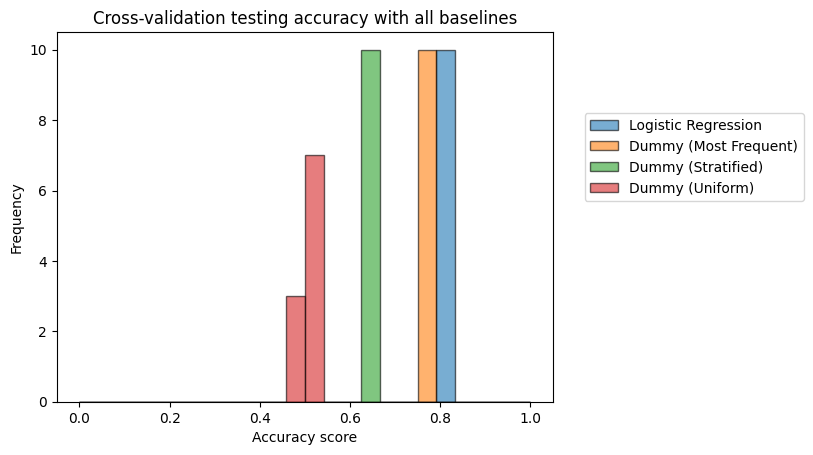

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Combine all four sets of scores into a single DataFrame
all_scores_df = pd.DataFrame({
    "Logistic Regression": scores,
    "Dummy (Most Frequent)": scores_dummy,
    "Dummy (Stratified)": scores_stratified,
    "Dummy (Uniform)": scores_uniform
})

# Define bins and plot
bins = np.linspace(start=0.0, stop=1.0, num=25)
all_scores_df.plot.hist(bins=bins, alpha=0.6, edgecolor="black")
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
plt.xlabel("Accuracy score")
plt.ylabel("Frequency")
_ = plt.title("Cross-validation testing accuracy with all baselines")
plt.show()